<a href="https://colab.research.google.com/github/Bianca-21-bit/Relat-rio/blob/main/Trabalho.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# <> ------------------------------------------------------
# <> Verificando se o pacote está instalado
# <> o símbolo % é para executar no bash
%pip show pycaret

Name: pycaret
Version: 3.3.2
Summary: PyCaret - An open source, low-code machine learning library in Python.
Home-page: https://github.com/pycaret/pycaret
Author: Moez Ali
Author-email: moez.ali@queensu.ca
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: category-encoders, cloudpickle, deprecation, imbalanced-learn, importlib-metadata, ipython, ipywidgets, jinja2, joblib, kaleido, lightgbm, markupsafe, matplotlib, nbformat, numba, numpy, pandas, plotly, plotly-resampler, pmdarima, psutil, pyod, requests, schemdraw, scikit-learn, scikit-plot, scipy, sktime, statsmodels, tbats, tqdm, wurlitzer, xxhash, yellowbrick
Required-by: 


In [ ]:
# <> ------------------------------------------------------
# <> Instalando o PyCaret 3.3.2 no Python 3.13 do Colab
# <> --no-deps => instala o PyCaret sem rebaixar numpy, pandas e scipy do Colab
%pip install -q pycaret==3.3.2 --no-deps

# <> Dependências do PyCaret (as que já existem no Colab são mantidas)
# <> scikit-learn 1.5.2 e joblib 1.3.2 são as versões compatíveis com o PyCaret 3.3.2
%pip install -q "scikit-learn==1.5.2" "joblib==1.3.2" "schemdraw==0.15" \
    pyod imbalanced-learn category-encoders lightgbm numba scikit-plot \
    yellowbrick plotly plotly-resampler statsmodels deprecation xxhash wurlitzer setuptools

In [ ]:
# <> ------------------------------------------------------
# <> Ajustes de compatibilidade do PyCaret 3.3.2 com Python 3.13 / numpy 2
# <> (só altera os arquivos da biblioteca instalada; pode rodar quantas vezes quiser)
import importlib.util, pathlib, re

# o módulo distutils foi removido do Python 3.12+; o setuptools fornece um substituto
DISTUTILS = (r'(?<!import setuptools  # distutils\n)from distutils\.version import LooseVersion',
             'import setuptools  # distutils\nfrom distutils.version import LooseVersion')

ajustes = {
    'pycaret': [
        # PyCaret bloqueia Python >= 3.12 na importação
        (r'elif sys\.version_info >= \(3, 12\):', 'elif False:'),
        # função que mudou de lugar no scikit-learn
        (r'from sklearn\.utils import _print_elapsed_time',
         'from sklearn.utils._user_interface import _print_elapsed_time'),
        # funções removidas no numpy 2
        (r'np\.product\(', 'np.prod('),
        (r'np\.NaN\b', 'np.nan'),
        DISTUTILS,
    ],
    'yellowbrick': [
        DISTUTILS,
    ],
    'scikitplot': [
        # função removida do scipy (usada pelo scikit-plot)
        (r'from scipy import interp\b', 'from numpy import interp'),
    ],
}

for pacote, regras in ajustes.items():
    pasta = pathlib.Path(importlib.util.find_spec(pacote).submodule_search_locations[0])
    for arquivo in pasta.rglob('*.py'):
        texto = original = arquivo.read_text(encoding='utf-8')
        for padrao, novo in regras:
            texto = re.sub(padrao, novo, texto)
        if texto != original:
            arquivo.write_text(texto, encoding='utf-8')
            print('Ajustado:', arquivo.relative_to(pasta.parent))

print('Pronto! O PyCaret já pode ser importado.')

Ajustado: pycaret/__init__.py
Ajustado: pycaret/utils/_dependencies.py
Ajustado: pycaret/internal/pipeline.py
Ajustado: pycaret/internal/patches/sklearn.py
Ajustado: pycaret/internal/preprocess/preprocessor.py
Ajustado: yellowbrick/style/colors.py
Ajustado: yellowbrick/style/rcmod.py
Ajustado: scikitplot/plotters.py
Ajustado: scikitplot/metrics.py
Pronto! O PyCaret já pode ser importado.


In [ ]:
import sys
import pycaret
import sklearn
import pandas as pd
import numpy as np

print("Python version:", sys.version.split()[0])
print("PyCaret version:", pycaret.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)
print("Numpy version:", np.__version__)

Python version: 3.13.18
PyCaret version: 3.3.2
Scikit-learn version: 1.5.2
Pandas version: 2.2.3
Numpy version: 2.1.3


In [ ]:
# <> ------------------------------------------------------
# <> Verificando se o pacote foi instalado
%pip show pycaret

Name: pycaret
Version: 3.3.2
Summary: PyCaret - An open source, low-code machine learning library in Python.
Home-page: https://github.com/pycaret/pycaret
Author: Moez Ali
Author-email: moez.ali@queensu.ca
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: category-encoders, cloudpickle, deprecation, imbalanced-learn, importlib-metadata, ipython, ipywidgets, jinja2, joblib, kaleido, lightgbm, markupsafe, matplotlib, nbformat, numba, numpy, pandas, plotly, plotly-resampler, pmdarima, psutil, pyod, requests, schemdraw, scikit-learn, scikit-plot, scipy, sktime, statsmodels, tbats, tqdm, wurlitzer, xxhash, yellowbrick
Required-by: 


Corrrigindo yellowbrick/style/colors

In [ ]:
from pathlib import Path

base = Path("/usr/local/lib/python3.13/dist-packages/yellowbrick")

for arquivo in base.rglob("*.py"):
    try:
        texto = arquivo.read_text(encoding="utf-8")
        original = texto

        texto = texto.replace(
            "from setuptools.version import LooseVersion",
            "from packaging.version import Version"
        )

        texto = texto.replace(
            'LooseVersion(mpl.__version__) >= "1.5.0"',
            'Version(mpl.__version__) >= Version("1.5.0")'
        )

        if texto != original:
            arquivo.write_text(texto, encoding="utf-8")
            print("Corrigido:", arquivo)

    except Exception as e:
        print("Erro:", arquivo, e)

Corrigido: /usr/local/lib/python3.13/dist-packages/yellowbrick/style/colors.py
Corrigido: /usr/local/lib/python3.13/dist-packages/yellowbrick/style/rcmod.py


In [ ]:
from pathlib import Path

base = Path("/usr/local/lib/python3.13/dist-packages/yellowbrick")

achou = False

for arquivo in base.rglob("*.py"):
    texto = arquivo.read_text(encoding="utf-8", errors="ignore")

    if "setuptools.version import LooseVersion" in texto:
        achou = True
        print("Ainda existe:", arquivo)

if not achou:
    print("Nenhuma ocorrência restante.")

Nenhuma ocorrência restante.


In [ ]:
from pathlib import Path

arquivo = Path(
    "/usr/local/lib/python3.13/dist-packages/yellowbrick/style/colors.py"
)

print(arquivo.exists())

for i, linha in enumerate(
    arquivo.read_text(encoding="utf-8").splitlines(),
    start=1
):
    if 30 <= i <= 40:
        print(f"{i}: {linha}")

True
30: 
31: 
32: # Check to see if matplotlib is at least sorta up to date
33: import setuptools  # distutils
34: from distutils.version import LooseVersion
35: 
36: mpl_ge_150 = Version(mpl.__version__) >= Version("1.5.0")
37: 
38: 
39: ##########################################################################
40: ## Color Utilities


In [ ]:
from pathlib import Path

arquivo = Path("/usr/local/lib/python3.13/dist-packages/yellowbrick/style/colors.py")

texto = arquivo.read_text(encoding="utf-8")

texto = texto.replace(
    "from distutils.version import LooseVersion",
    "from packaging.version import Version"
)

arquivo.write_text(texto, encoding="utf-8")

print("colors.py corrigido")

colors.py corrigido


In [ ]:
from pathlib import Path

arquivo = Path("/usr/local/lib/python3.13/dist-packages/yellowbrick/style/rcmod.py")

texto = arquivo.read_text(encoding="utf-8")

texto = texto.replace(
    "from setuptools.version import LooseVersion",
    "from packaging.version import Version"
)

texto = texto.replace(
    "from distutils.version import LooseVersion",
    "from packaging.version import Version"
)

texto = texto.replace(
    'LooseVersion(mpl.__version__) >= "1.5.0"',
    'Version(mpl.__version__) >= Version("1.5.0")'
)

arquivo.write_text(texto, encoding="utf-8")

print("rcmod.py corrigido")

rcmod.py corrigido


In [ ]:
from pathlib import Path

base = Path("/usr/local/lib/python3.13/dist-packages/yellowbrick")

for arquivo in base.rglob("*.py"):
    try:
        texto = arquivo.read_text(encoding="utf-8")
        if "from setuptools.version import LooseVersion" in texto:
            print(arquivo)
    except:
        pass

In [ ]:
import yellowbrick
print("Yellowbrick OK")

Yellowbrick OK


Importando Bibliotecas


In [ ]:
import sys
import numpy
import sklearn
import setuptools

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("Setuptools:", setuptools.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.1.3
Scikit-Learn: 1.5.2
Setuptools: 80.10.2


In [ ]:
# <> -----------------------------------------------------
# Lendo as bibliotecas necessárias

# <> -----------------------------
# <> Bibliotecas dos algoritmos
from pycaret.classification import *
from sklearn.tree import plot_tree
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score, classification_report
from sklearn.tree import export_text

# <> Bibliotecas de Visualização
import seaborn as sns
import matplotlib.pyplot as plt

# <> Biliotecas para manipulação com dados
import pandas as pd

Forma 1 - Utilizando dados separados para treino e teste manualmente

In [ ]:
import pandas as pd

arquivo = pd.read_csv("/content/sleep_debt_screen_time.csv")

In [ ]:
arquivo.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


In [ ]:
print(arquivo.columns.tolist())

['user_id', 'age', 'gender', 'chronotype', 'occupation', 'bedtime_hour', 'screen_time_before_bed_min', 'primary_app_category', 'screen_brightness_pct', 'blue_light_filter_on', 'caffeine_intake_mg', 'caffeine_last_hour', 'physical_activity_min', 'room_temperature_f', 'ambient_noise_db', 'sleep_onset_latency_min', 'total_sleep_hours', 'rem_sleep_pct', 'deep_sleep_pct', 'awakenings_count', 'sleep_efficiency_pct', 'next_day_fatigue_score', 'sleep_debt_category']


In [ ]:
from sklearn.model_selection import train_test_split

# X = todas as colunas exceto a variável alvo
X = arquivo.drop("sleep_debt_category", axis=1)

# y = variável alvo
y = arquivo["sleep_debt_category"]

# Divisão treino/teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=10,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)


Treino: (6800, 22)
Teste: (1700, 22)


In [ ]:
# <> ------------------------------------------------------
# <> Verificando se os tipos foram lidos corretamente
print(X_train.dtypes)
print(X_test.dtypes)

user_id                         int64
age                             int64
gender                         object
chronotype                     object
occupation                     object
bedtime_hour                  float64
screen_time_before_bed_min      int64
primary_app_category           object
screen_brightness_pct           int64
blue_light_filter_on             bool
caffeine_intake_mg              int64
caffeine_last_hour            float64
physical_activity_min           int64
room_temperature_f            float64
ambient_noise_db              float64
sleep_onset_latency_min       float64
total_sleep_hours             float64
rem_sleep_pct                 float64
deep_sleep_pct                float64
awakenings_count                int64
sleep_efficiency_pct          float64
next_day_fatigue_score        float64
dtype: object
user_id                         int64
age                             int64
gender                         object
chronotype                     objec

In [ ]:
X_train.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score
6547,6548,19,Female,Night Owl,Professional,0.13,34,Social Media,66,True,...,1,71.5,45.9,28.5,7.67,17.1,18.1,3,79.6,3.39
3496,3497,36,Female,Intermediate,Professional,22.92,41,Gaming,36,False,...,19,73.1,28.1,24.9,7.21,19.4,18.2,2,87.7,3.24
2785,2786,24,Male,Intermediate,Freelancer,1.12,38,Short-Form Video,88,False,...,1,71.9,42.6,39.2,6.95,15.1,12.7,0,84.6,4.11
6196,6197,16,Female,Intermediate,Unemployed,23.50,113,Short-Form Video,90,False,...,5,68.7,35.7,43.8,6.01,13.3,10.9,0,74.5,6.92
2345,2346,38,Male,Intermediate,Student,23.32,29,Social Media,65,False,...,90,71.4,12.2,35.2,6.44,16.1,19.8,0,87.4,4.51


In [ ]:
# <> Juntando as variável alvo aos dados de treino
train_data = X_train.copy()
train_data['sleep_debt_category'] = y_train

# <> Juntando as variável alvo aos dados de teste
test_data = X_test.copy()
test_data['sleep_debt_category'] = y_test

In [ ]:
# <> ----------------------------------------------------------
# <> Configurar o ambiente PyCaret com dados de treino e teste informados manualmente
from pycaret.classification import setup

cdt = setup(
    data=train_data,
    target='sleep_debt_category',
    test_data=test_data,
    session_id=10,
    index=False
)

,Description,Value
0,Session id,10
1,Target,sleep_debt_category
2,Target type,Multiclass
3,Target mapping,"Mild: 0, Moderate: 1, No Debt: 2, Severe: 3"
4,Original data shape,"(8500, 23)"
5,Transformed data shape,"(8500, 37)"
6,Transformed train set shape,"(6800, 37)"
7,Transformed test set shape,"(1700, 37)"
8,Numeric features,17
9,Categorical features,4


In [ ]:
# <> -----------------------------------------------------------
# <> Criando o modelo 'dt' : Decision Tree
decision_tree_model = create_model('dt', max_depth = 3, min_samples_split = 2, cross_validation = False)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Test,0.7782,0.8534,0.7782,0.8429,0.7611,0.5986,0.6525


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

* Accuracy = 77,82%: o modelo
classificou corretamente cerca de 78% das amostras.
* AUC = 0,8534: excelente capacidade de separação entre as classes. Valores acima de 0,80 geralmente são considerados muito bons.
* Precision = 84,29%: quando o modelo faz uma previsão, ele tende a acertar bastante.
* Recall = 77,82%: o modelo encontra cerca de 78% dos casos reais de cada classe.
* F1-Score = 76,11%: equilíbrio entre precisão e recall.
* Kappa = 0,5986: concordância moderada a substancial acima do acaso.
* MCC = 0,6525: mostra uma boa qualidade geral da classificação, especialmente quando há desbalanceamento entre classes



In [ ]:
# <> ------------------------------------------------------------
# <> Visualizando o modelo
print(decision_tree_model)

DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=3, max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, random_state=10, splitter='best')


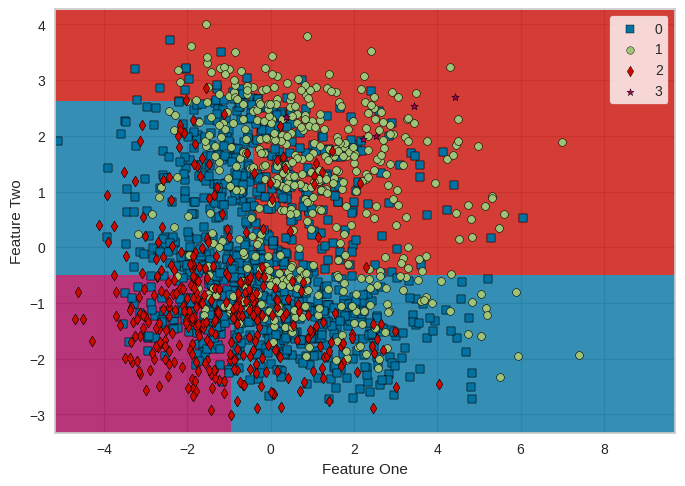

In [ ]:
# <> -------------------------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(decision_tree_model, plot = 'boundary')

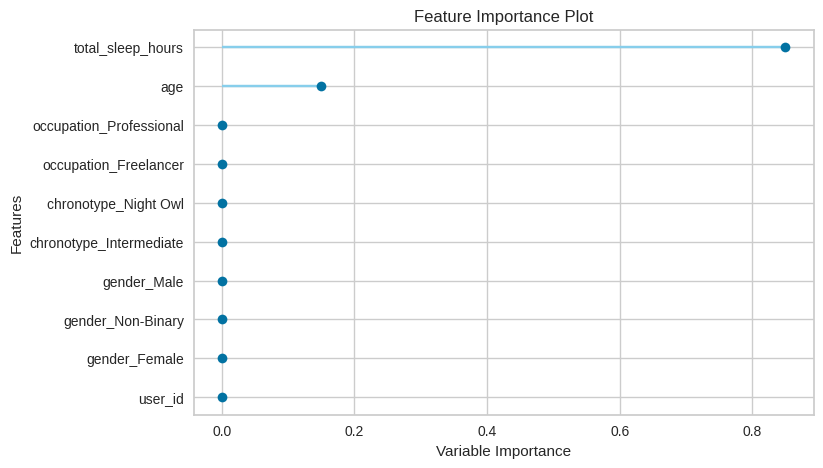

In [ ]:
# <> -------------------------------------------------------------
# <> Visualizando em forma de Gráfico
# <> As variáveis mais importantes
plot_model(decision_tree_model, plot = 'feature')

In [ ]:
# <> -----------------------------------------------------------
# <> Visualizando a estrutura da Árvore
# <> feature_names = nomes das variáveis esplicativas (A e B), sem a coluna sleep_debt_category)
estrutura_DT = export_text(decision_tree_model, feature_names=list(get_config('X_train_transformed').columns))
print(estrutura_DT)

|--- total_sleep_hours <= 6.01
|   |--- age <= 44.50
|   |   |--- total_sleep_hours <= 4.54
|   |   |   |--- class: 3
|   |   |--- total_sleep_hours >  4.54
|   |   |   |--- class: 1
|   |--- age >  44.50
|   |   |--- total_sleep_hours <= 5.51
|   |   |   |--- class: 1
|   |   |--- total_sleep_hours >  5.51
|   |   |   |--- class: 0
|--- total_sleep_hours >  6.01
|   |--- total_sleep_hours <= 8.01
|   |   |--- age <= 24.50
|   |   |   |--- class: 0
|   |   |--- age >  24.50
|   |   |   |--- class: 0
|   |--- total_sleep_hours >  8.01
|   |   |--- class: 2



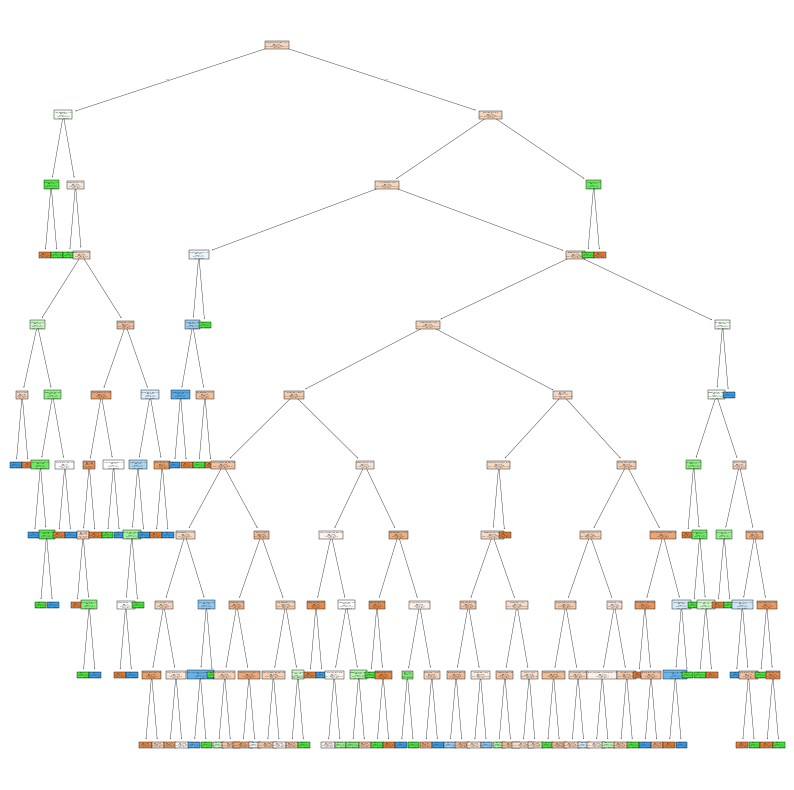

In [ ]:
# <> -----------------------------------------------------------
# <> Plotar a árvore de decisão
plt.figure(figsize=(10,10))
plot_tree(decision_tree_model, filled=True, feature_names=list(get_config('X_train_transformed').columns),
          class_names=sorted(y_test.unique()))
plt.show()

In [ ]:
# <> -----------------------------------------------------------
# <> Fazendo predição do modelo usando o DataFrame de teste completo
dt_testing_pred = predict_model(decision_tree_model, data = test_data)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Decision Tree Classifier,0.7782,0.8534,0.7782,0.8429,0.7611,0.5986,0.6525


Resumo das Métricas:

*  Accuracy: Mede a taxa de acerto geral
*  AUC: Mede a capacidade de discriminação do modelo
*  Recall: Mede a capacidade de identificar positivos reais
*  Precision: Mede a confiabilidade das previsões positivas
*  F1: Equilibra Precision e Recall
*  Kappa: Mede a concordância ajustada ao acaso
*  MCC: Mede a correlação entre previsões e valores reais, robusta e desbalanceamentos



In [ ]:
# <> -----------------------------------------------------
# <> Visualizando Cabeçalho do Data.Frame
dt_testing_pred.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category,prediction_label,prediction_score
0,6496,31,Male,Night Owl,Professional,1.92,229,News,76,True,...,35.500000,5.50,17.600000,17.200001,4,78.199997,5.59,Moderate,Moderate,0.9910
1,4800,35,Male,Night Owl,Student,23.25,158,Messaging,87,True,...,30.299999,5.58,16.600000,17.799999,0,81.500000,5.93,Moderate,Moderate,0.9910
2,1537,33,Female,Night Owl,Professional,0.45,18,Short-Form Video,74,True,...,30.200001,5.73,16.799999,17.100000,2,81.199997,5.54,Moderate,Moderate,0.9910
3,1341,29,Male,Intermediate,Professional,23.85,68,Short-Form Video,85,True,...,40.500000,6.41,18.000000,13.400000,2,79.099998,5.58,Mild,Mild,0.7195
4,5551,18,Male,Night Owl,Professional,0.78,74,Gaming,44,False,...,39.900002,7.23,14.200000,19.500000,1,86.800003,4.55,Mild,Mild,0.6595


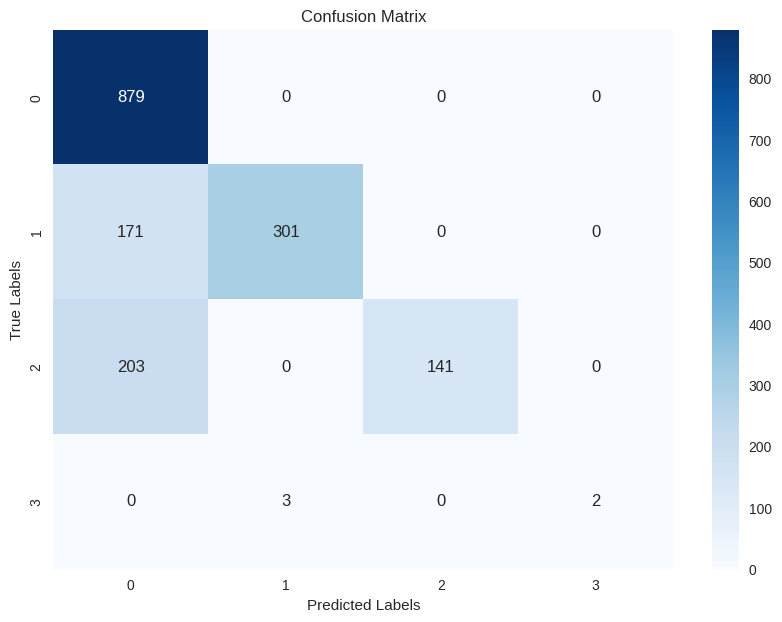

Accuracy: 0.778235294117647
Kappa: 0.5985872576350783
Classification Report: 
              precision    recall  f1-score   support

        Mild       0.70      1.00      0.82       879
    Moderate       0.99      0.64      0.78       472
     No Debt       1.00      0.41      0.58       344
      Severe       1.00      0.40      0.57         5

    accuracy                           0.78      1700
   macro avg       0.92      0.61      0.69      1700
weighted avg       0.84      0.78      0.76      1700



In [ ]:
# Supondo que 'true_labels' seja a coluna de rótulos verdadeiros e 'predicted_labels' a coluna de rótulos previstos
true_labels = dt_testing_pred['sleep_debt_category']
predicted_labels = dt_testing_pred['prediction_label']

# Calcular a matriz de confusão
conf_matrix = confusion_matrix(true_labels, predicted_labels)

# Plotar a matriz de confunsão
plt.figure(figsize=(10,7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Calcular Acurácia
accuracy = accuracy_score(true_labels, predicted_labels)

# Calcular coeficiente Kappa
kappa = cohen_kappa_score(true_labels, predicted_labels)

# Gerar relatório de classificação
classification_rep = classification_report(true_labels, predicted_labels)

# Exibir as métricas
print(f'Accuracy: {accuracy}')
print(f'Kappa: {kappa}')
print('Classification Report: ')
print(classification_rep)


Forma 2 - Passando os dados e fazendo separação de treino e teste e usando k-fold automatizados

In [ ]:
# <> ---------------------------------------------------------
# <> Lendo um dataset Completo
url_dat = '/content/sleep_debt_screen_time.csv' # url do dataset de treino

dados_dat = pd.read_csv(url_dat, sep=",") # dados

In [ ]:
# <> ---------------------------------------------------------
# <> Verificando tipos das variáveis
dados_dat.dtypes

,0
user_id,int64
age,int64
gender,object
chronotype,object
occupation,object
bedtime_hour,float64
screen_time_before_bed_min,int64
primary_app_category,object
screen_brightness_pct,int64
blue_light_filter_on,bool


In [ ]:
# <> Iniciando a configuração do modelo
# <> e informando a variável resposta
# <> session_id => para reprodutibilidade
clf = setup(data = dados_dat, target = 'sleep_debt_category', session_id = 12345)

,Description,Value
0,Session id,12345
1,Target,sleep_debt_category
2,Target type,Multiclass
3,Target mapping,"Mild: 0, Moderate: 1, No Debt: 2, Severe: 3"
4,Original data shape,"(8500, 23)"
5,Transformed data shape,"(8500, 37)"
6,Transformed train set shape,"(5950, 37)"
7,Transformed test set shape,"(2550, 37)"
8,Numeric features,17
9,Categorical features,4


In [ ]:
# <> -------------------------------------------------------
# <> Criação do Modelo com Árvore de Decisão
decision_tree_model = create_model('dt', max_depth = 10, fold = 5)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5067,0.5062,0.5067,0.4256,0.3853,0.0203,0.0351
1,0.4723,0.5032,0.4723,0.3721,0.3864,0.0016,0.0021
2,0.4899,0.4997,0.4899,0.4004,0.3950,0.0145,0.0198
3,0.4790,0.5039,0.4790,0.3774,0.3751,-0.0146,-0.0213
4,0.4622,0.4962,0.4622,0.3725,0.3846,-0.0134,-0.0164
Mean,0.4820,0.5018,0.4820,0.3896,0.3853,0.0017,0.0039
Std,0.0153,0.0035,0.0153,0.0208,0.0063,0.0142,0.0213


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

In [ ]:
# <> --------------------------------------------------------
# <> Visualizando o modelo
print(decision_tree_model)


DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=10, max_features=None, max_leaf_nodes=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, random_state=12345, splitter='best')


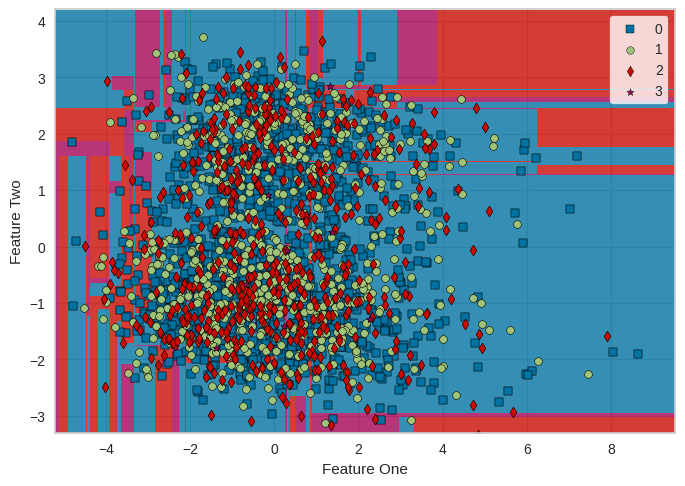

In [ ]:
# <> -----------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(decision_tree_model, plot = 'boundary')

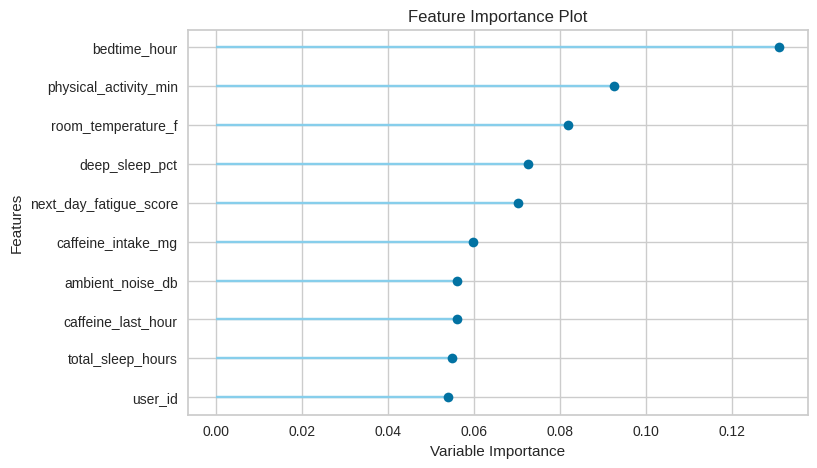

In [ ]:
# <> ----------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(decision_tree_model, plot = 'feature')

As árvores de Decisão
OBS.: Em cada código vemos uma maneira "diferente" em relação ao visual.

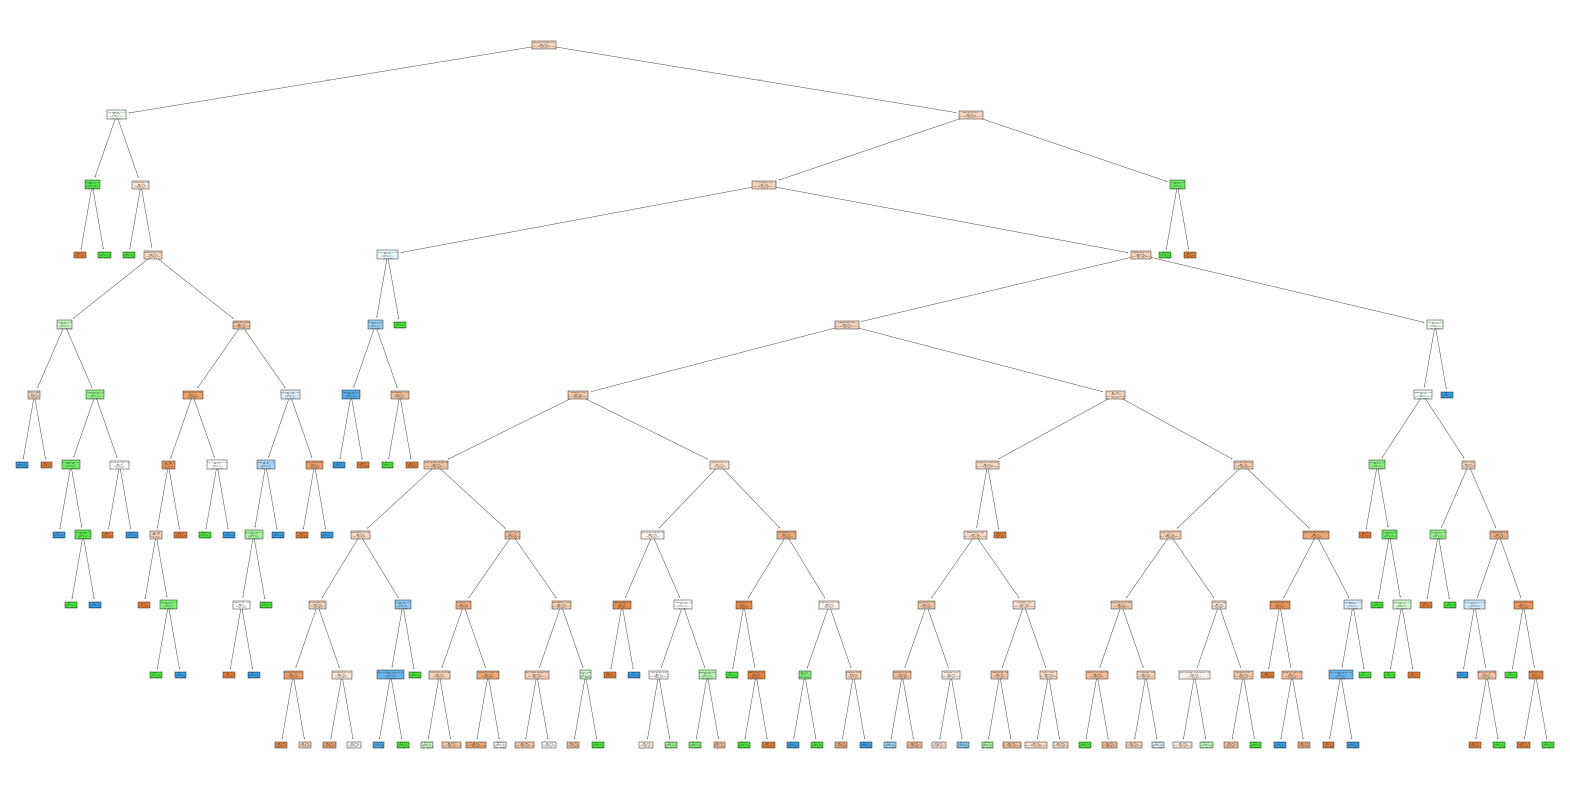

In [ ]:
# <> ---------------------------------------------------
# <> Plotar a árvore de decisão
plt.figure(figsize=(20, 10))
plot_tree(decision_tree_model, filled=True, feature_names=list(get_config('X_train_transformed').columns),
          class_names=sorted(y_test.unique())) # Ajustado para obter as classes diretamente de y_test
plt.show()

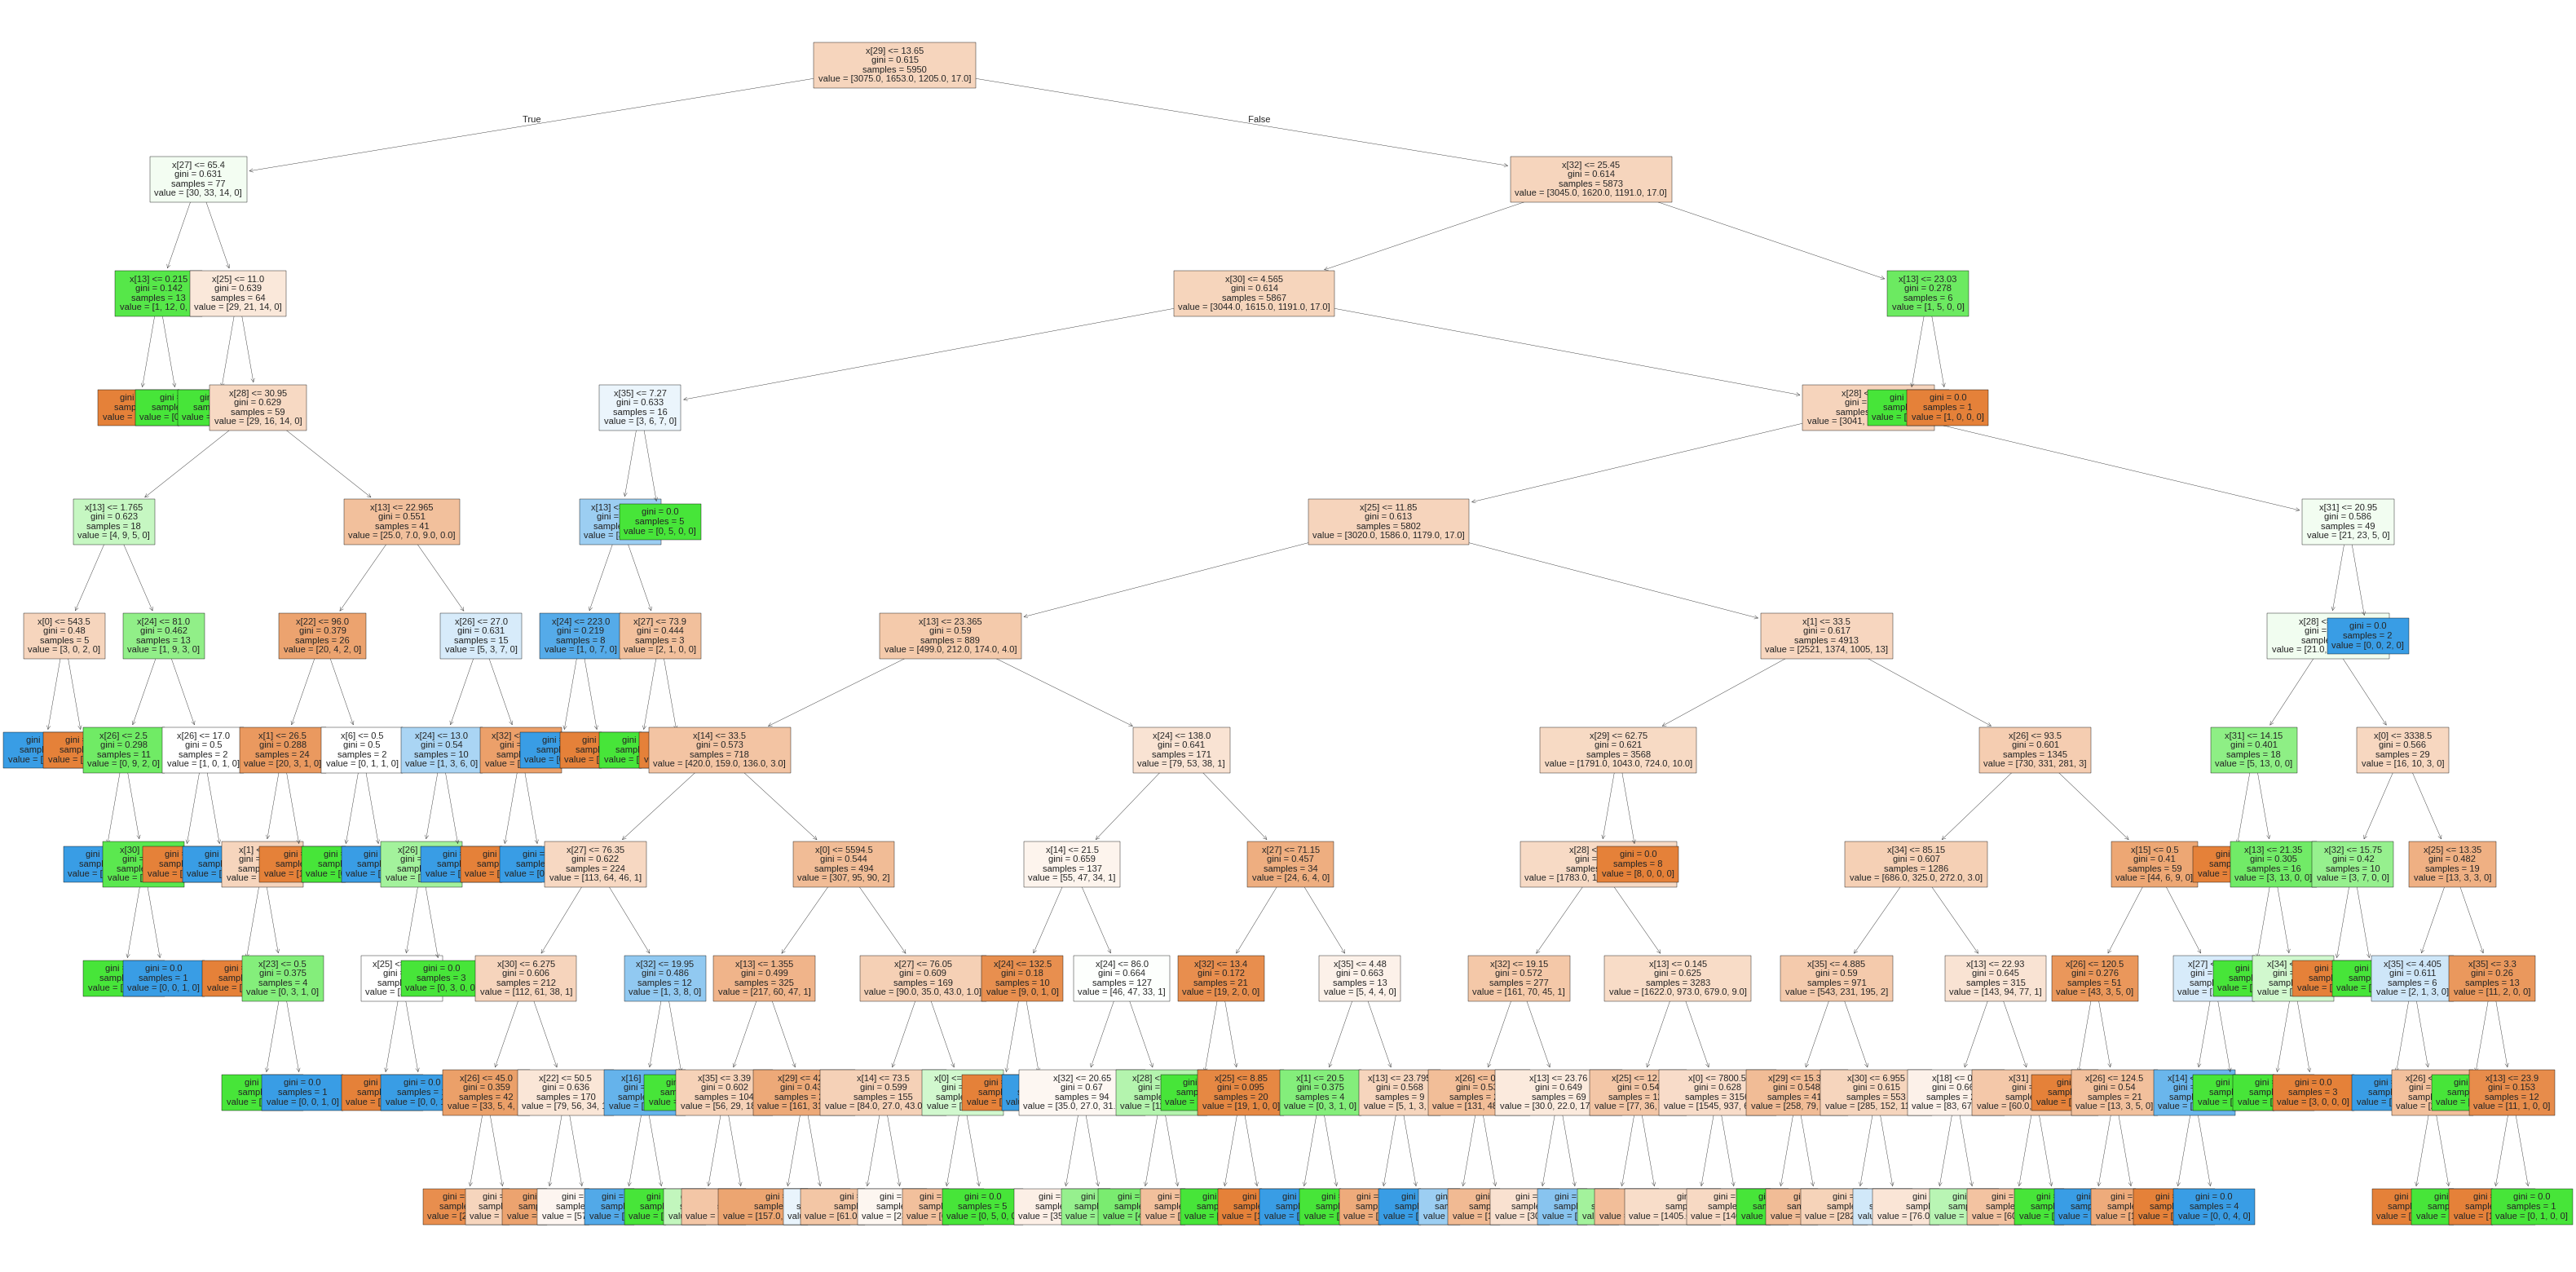

In [ ]:
# Modelo SVG é um formato vetoria
plt.figure(figsize=(40, 20))
tree.plot_tree(decision_tree_model, filled=True, fontsize=8)

plt.savefig("arvore.svg", bbox_inches="tight")
plt.show()

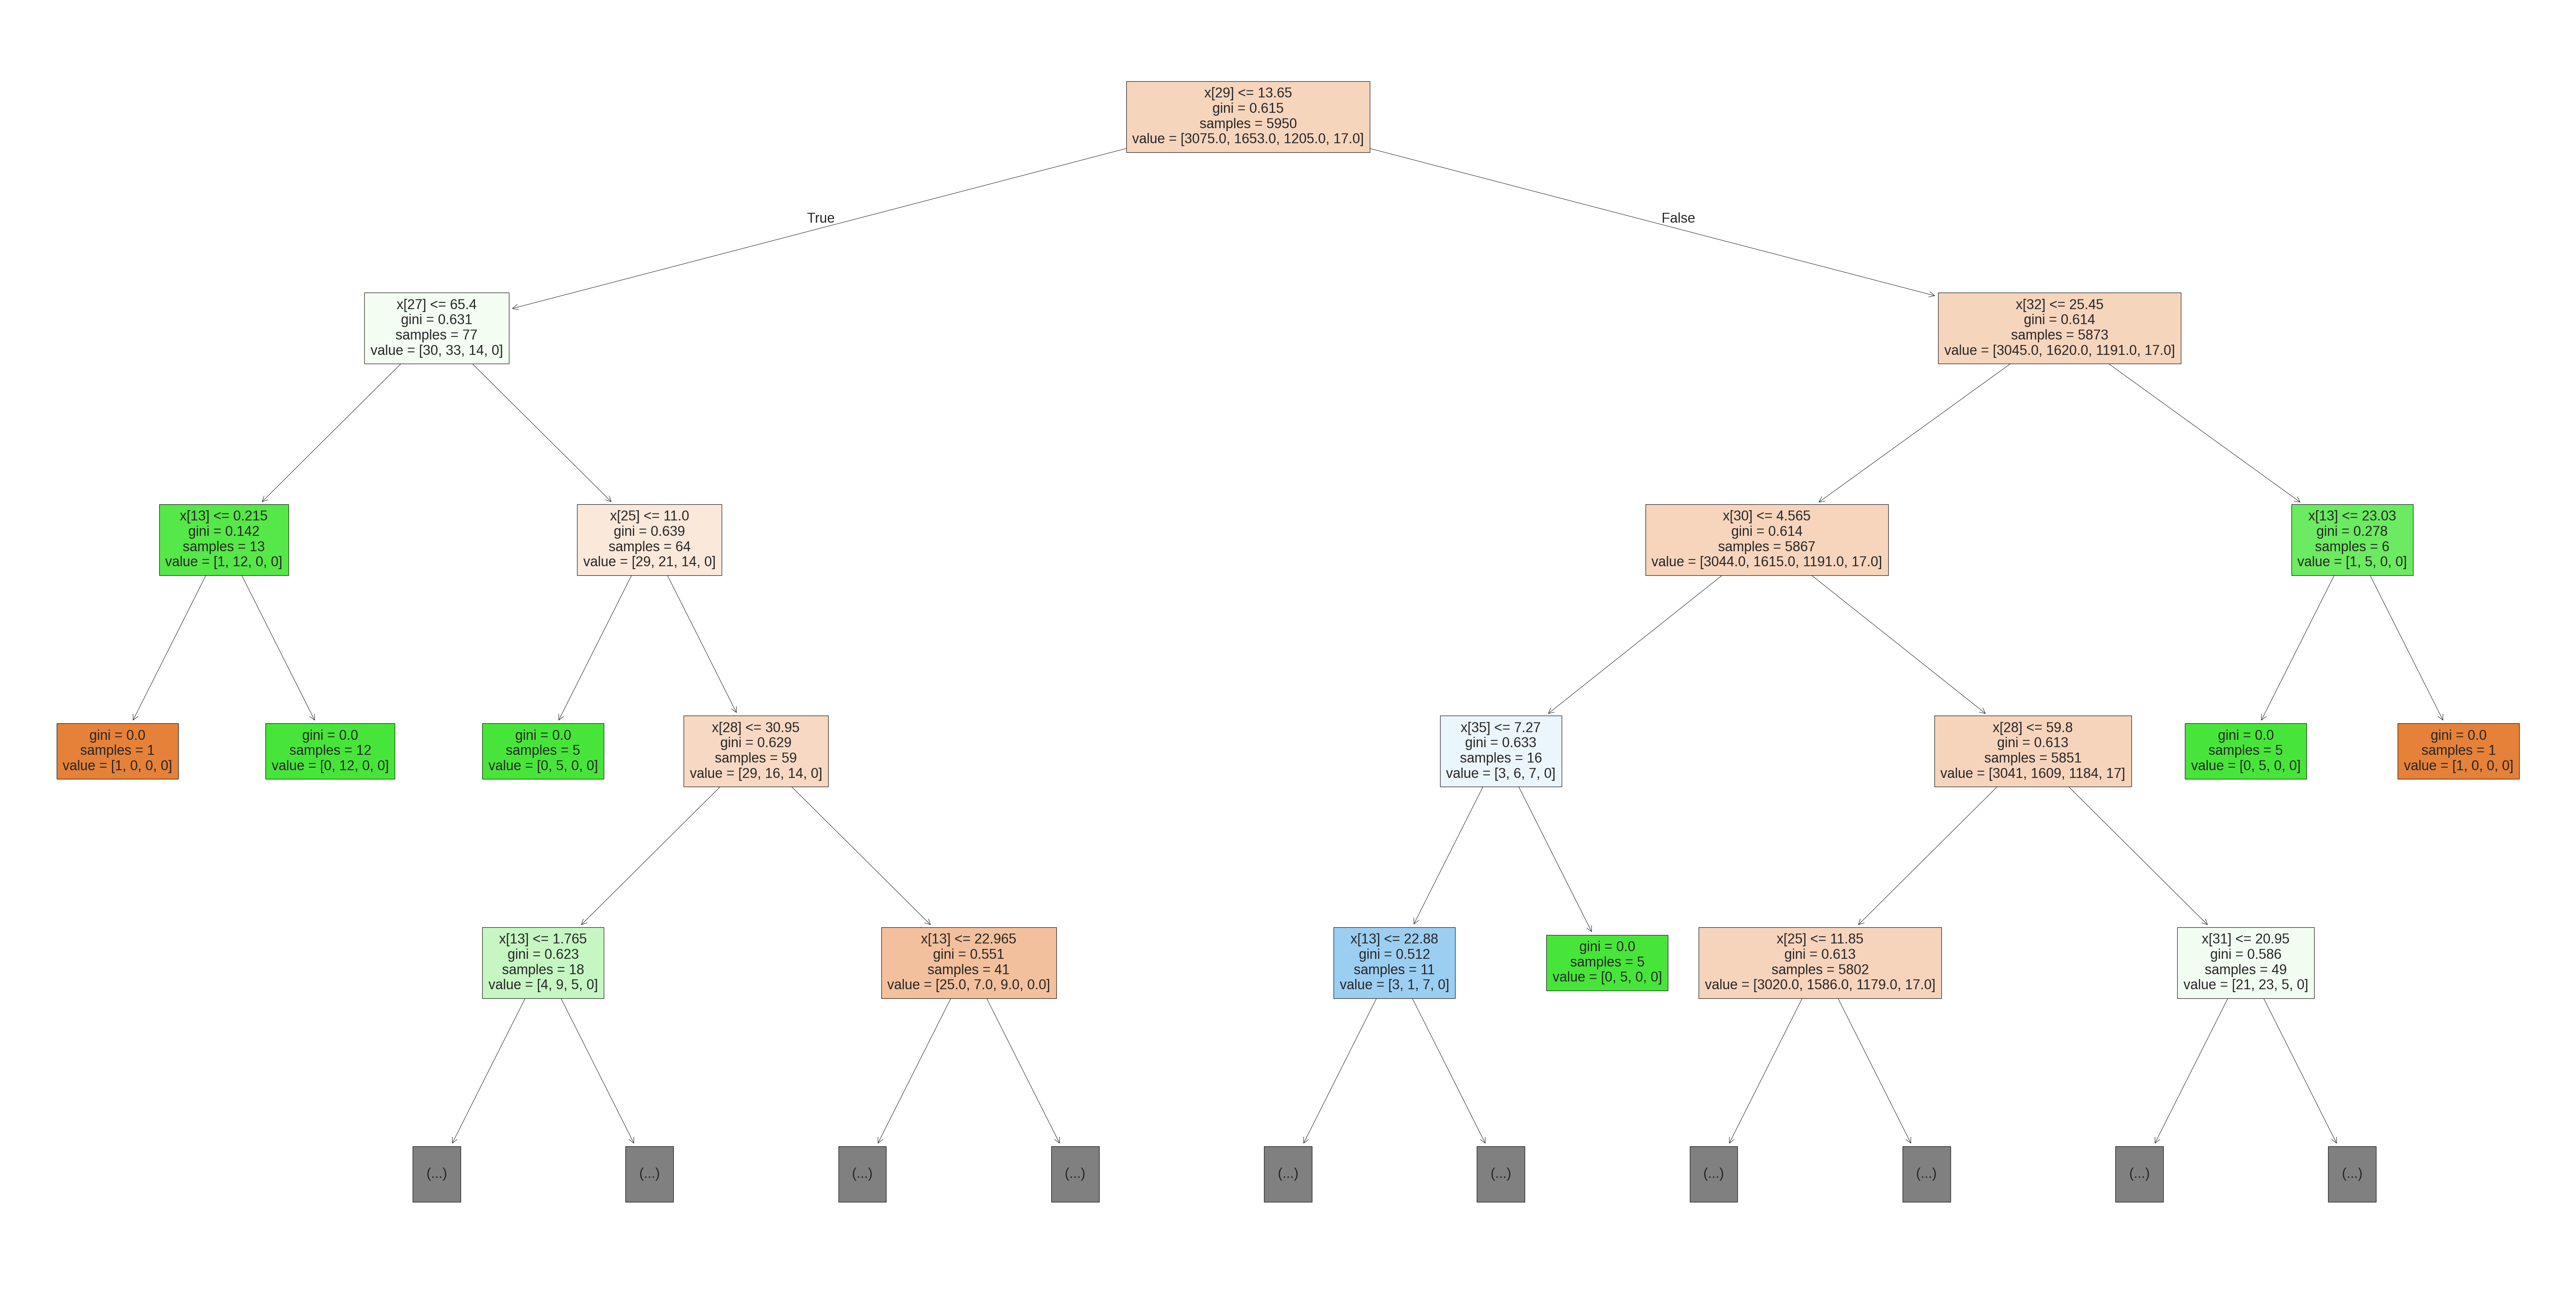

In [ ]:
# <> O plot_tree() do scikit-learn o gráfico está tentando desenhar toda a estrutura
# da árvore dentro do espaço disponível da figura. Quando a árvore tem muitos nós
# nas camadas finais, ele reduz automaticamente o tamanho visual dos nós para conseguir
# acomodar tudo
# <> O plot_tree() desenha esses nós como folhas "compactadas", geralmente menores e com reticências(...)
# em algumas versões.
plt.figure(figsize=(30,15), dpi=300)

tree.plot_tree(
    decision_tree_model,
    filled=True,
    max_depth=4, # Esse parâmetro só limita a visualização até o nível 4.
    fontsize=9
)

plt.show()

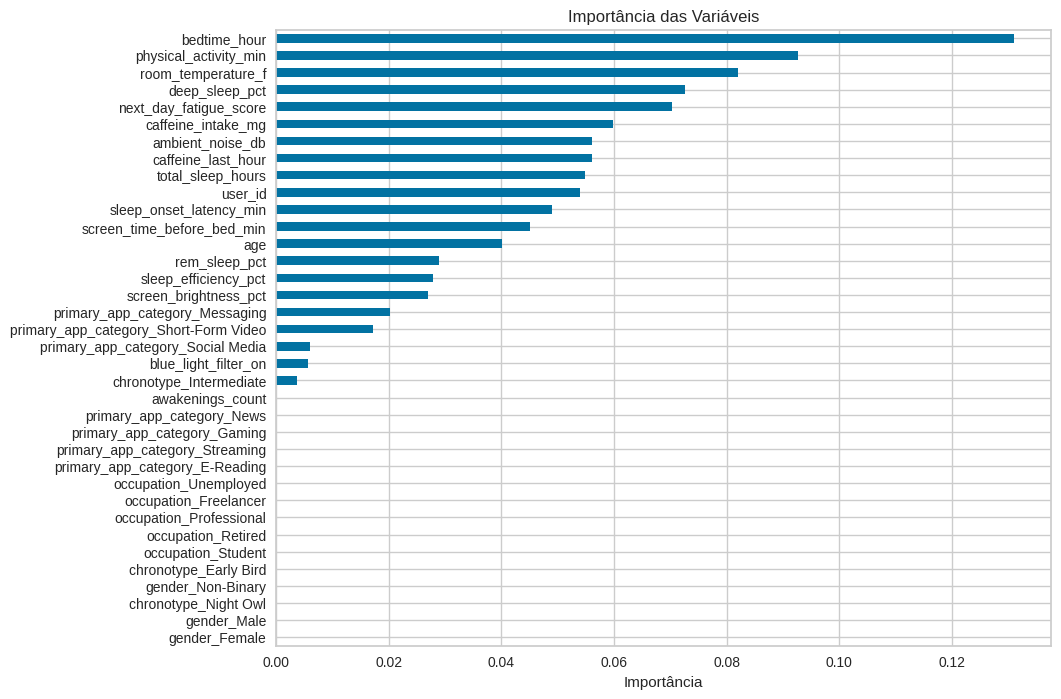

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Obtendo as colunas transformadas pelo pipeline do PyCaret (36 colunas)
features_transformadas = get_config('X_train_transformed').columns

importancias = pd.Series(
    decision_tree_model.feature_importances_,
    index=features_transformadas
)

importancias.sort_values().plot(
    kind='barh',
    figsize=(10,8)
)

plt.title('Importância das Variáveis')
plt.xlabel('Importância')
plt.show()

# Observamos que a variável bedtime_hour foi a mais relevante para as decisões da árvore. Em contrapartida, diversas variáveis apresentam importância nula, indicando que não foram utilizadas nas divisões realizadas pela árvore de decisão.
## O modelo concetrou suas decisões em um subconjunto específico de atributos com maior poder discriminatório.

In [ ]:
# <> ------------------------------------------------------
# <> Otimizar o modelo
tuned_dt = tune_model(decision_tree_modelimport pandas as pd

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.5176,0.5000,0.5176,0.2680,0.3531,0.0000,0.0000
1,0.5176,0.5000,0.5176,0.2680,0.3531,0.0000,0.0000
2,0.5176,0.5000,0.5176,0.2680,0.3531,0.0000,0.0000
3,0.5176,0.5000,0.5176,0.2680,0.3531,0.0000,0.0000
4,0.5176,0.5000,0.5176,0.2680,0.3531,0.0000,0.0000
5,0.5160,0.5000,0.5160,0.2662,0.3512,0.0000,0.0000
6,0.5160,0.5000,0.5160,0.2662,0.3512,0.0000,0.0000
7,0.5160,0.5000,0.5160,0.2662,0.3512,0.0000,0.0000
8,0.5160,0.5000,0.5160,0.2662,0.3512,0.0000,0.0000


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 10 folds for each of 10 candidates, totalling 100 fits


In [ ]:
# <> ----------------------------------------------------
# <> Visualizando o modelo
print(tuned_dt)

DecisionTreeClassifier(ccp_alpha=0.0, class_weight=None, criterion='gini',
                       max_depth=np.int64(2), max_features='log2',
                       max_leaf_nodes=None, min_impurity_decrease=0.3,
                       min_samples_leaf=2, min_samples_split=7,
                       min_weight_fraction_leaf=0.0, monotonic_cst=None,
                       random_state=12345, splitter='best')


Observações:
* criterion ='gini' => A árvore usa o índice Gini para escolher as decisões.

* max_depth = 2 => A árvore é bem pequena e fácil de interpretar. ( Como regra geral:
* profundidade pequena -> modelo mais simples
* profundidade grande -> modelo mais complexo)

* max_features = 'log2' => Em cada divisão, a árvore não testa todas as variáveis.

* min_impurity_decrease = 0.3 => Uma divisão só ocorre se houver uma melhoria de pelo menos 0.3

* min_samples_slit = 7 => Um nó só pode ser dividido se tiver pelo menos 7 amostras.

* min_samples_leaf = 2 => Cada folha precisa ter pelo menos 2 observações.

* splitter = 'best' => A árvore testa as possibilidades disponíveis e escolhe a melhor divisão.

* random_state = 12345 => Define a semente aleatória. (Isso garante que, ao executar o código novamente, você obtenha exatamente a mesma árvore).







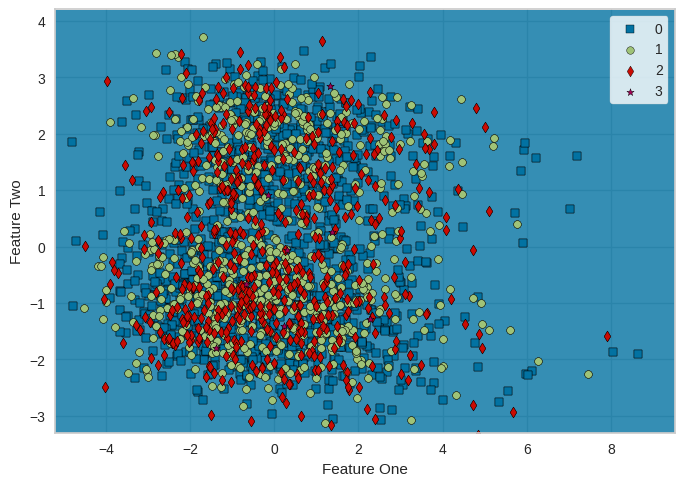

In [ ]:
# <> -----------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(tuned_dt, plot = 'boundary')


OBS.: A predominância de uma única cor no gráfico de fronteira de decisão indica que o modelo tende a classificar a maior parte das observações em uma única classe. Esse compartamento pode ser associado ao forte desbalanceamento da base de dados, levando a árvore priorizar a classe majoritária durante o processo de classificação.
E além disso, os parâmetros max_deoth=2 e min_impurity_decrease=0.3, tornam o modelo mais conversador, restringindo o crescimento da árvore e reduzindo a quantidade da árvore e reduzindo a quantidade de divisões realizadas.

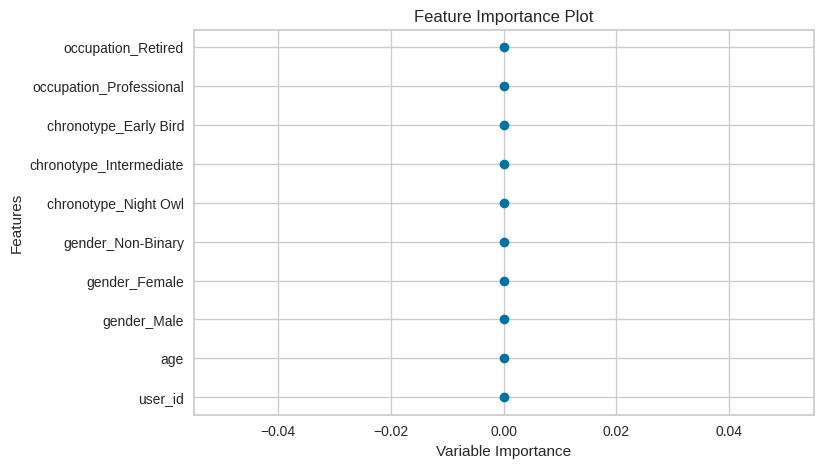

In [ ]:
# <> -------------------------------------------------
# <> Visualizando em forma de Gráfico
plot_model(tuned_dt, plot = 'feature')

Considerando o forte desbalanceamento da base, o max_deoth=2 e min_impurity_decrease=0.3, supeitando que a árvore ficou tão conservadora que está realizando poucas ou nenhuma divisão importante.

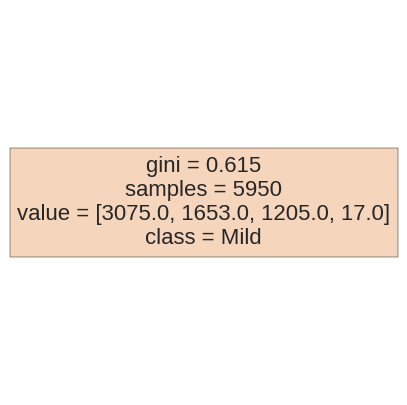

In [ ]:
# <> ------------------------------------------------------------
# <> Extrair o modelo treinado
trained_model = tuned_dt

# Plotar a árvore de decisão
plt.figure(figsize=(5,5))
plot_tree(trained_model, filled=True, feature_names=list(get_config('X_train_transformed').columns),
         class_names=sorted(y_test.unique()))
plt.show()

Observamos que com o forte desbalaceamento da base de dados, a árvore acabou ficando muito conservadora, levando a nenhuma divisão.

In [ ]:
# <> ------------------------------------------------
# <> Lendo dados de teste
url_dat_test = '/content/sleep_debt_screen_time.csv'  # url do dataset de treino

two_class_dat_test = pd.read_csv(url_dat_test, sep=",")  # dados

In [ ]:
# <> --------------------------------- # A parte de avaliar é no teste
# <> Fazendo predição do modelo
dt_testing_pred = predict_model(tuned_dt, data = two_class_dat_test)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Decision Tree Classifier,0.5168,0,0.5168,0.2671,0.3522,0.0000,0.0000


Os resultados obtidos indicam um desempenho insatisfatório do modelo de Árvore de Decisão. Embora a acurácia tenha sido de 51,68%, as métricas Kappa e MCC apresentaram valor nulo, sugerindo que o classificador não foi capaz de estabelecer uma relação efetiva entre as previsões e os valores reais. Além disso, o valor de AUC igual a 0 evidencia uma capacidade discriminatória inexistente ou possivelmente comprometida pelo forte desbalanceamento da base de dados. Esse comportamento é coerente com a predominância de uma única classe observada na fronteira de decisão, indicando que o modelo tende a favorecer a classe majoritária. Ademais, os hiperparâmetros adotados, especialmente max_depth = 2 e min_impurity_decrease = 0,3, tornam a árvore mais conservadora, limitando sua capacidade de aprender padrões mais complexos presentes nos dados

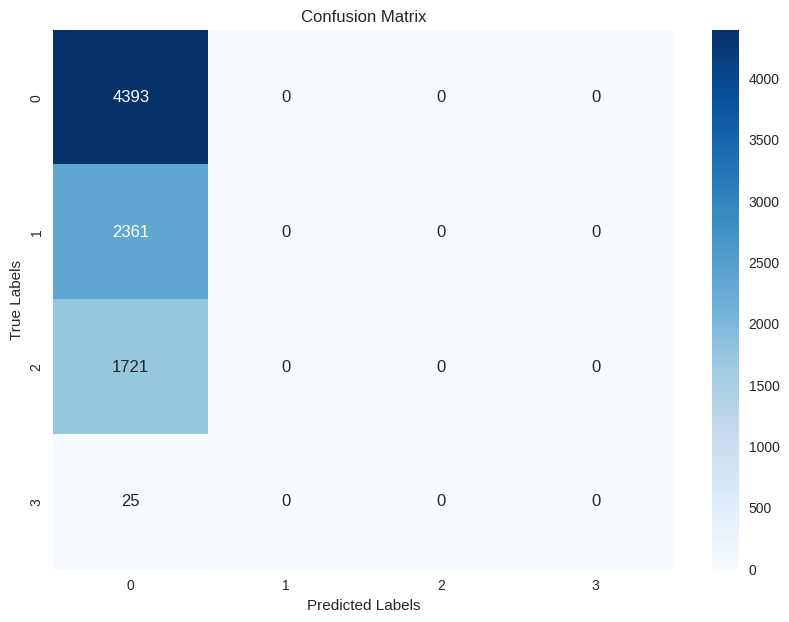

Accuracy: 0.5168235294117647
Kappa: 0.0
Classification Report:
              precision    recall  f1-score   support

        Mild       0.52      1.00      0.68      4393
    Moderate       0.00      0.00      0.00      2361
     No Debt       0.00      0.00      0.00      1721
      Severe       0.00      0.00      0.00        25

    accuracy                           0.52      8500
   macro avg       0.13      0.25      0.17      8500
weighted avg       0.27      0.52      0.35      8500



In [ ]:
# Supondo que 'true_labels' seja a coluna de rótulos verdadeiros e 'predicted_labels' a coluna de rótulos previstos
true_labels = dt_testing_pred['sleep_debt_category']
predicted_labels = dt_testing_pred['prediction_label']

# Calcular a matriz de confusão
conf_matrix = confusion_matrix(true_labels, predicted_labels)

# Plotar a matriz de confusão
plt.figure(figsize=(10,7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Calcular acurácia
accuracy = accuracy_score(true_labels, predicted_labels)

# Calcular coeficiente Kappa
kappa = cohen_kappa_score(true_labels, predicted_labels)

# Gerar relatório de classificação
classification_rep = classification_report(true_labels, predicted_labels)

# Exibir as métricas
print(f'Accuracy: {accuracy}')
print(f'Kappa: {kappa}')
print('Classification Report:')
print(classification_rep)

Os resultados obtidos sugerem que a Árvore de Decisão não apresentou desempenho satisfatório para o problema analisado. As métricas AUC, Kappa e MCC apresentaram valores nulos, indicando baixa capacidade de discriminação e classificação das observações. Adicionalmente, a predominância de uma única classe na fronteira de decisão evidencia uma forte influência do desbalanceamento da base de dados. Embora as Árvores de Decisão sejam modelos amplamente utilizados em tarefas de classificação, a configuração adotada neste estudo, associada às características do conjunto de dados, resultou em um modelo excessivamente conservador e com reduzida capacidade preditiva.

CONCLUSÃO DO MODELO ÁRVORE DE DECISÃO:

Os resultados obtidos com a separação manual dos conjuntos de treinamento e teste demonstraram desempenho significativamente superior ao observado na versão ajustada do modelo. A Árvore de Decisão apresentou acurácia de 77,82% e AUC de 85,34%, indicando boa capacidade de discriminação entre as classes. Além disso, os valores de Precision (84,29%), F1-Score (76,11%), Kappa (0,5986) e MCC (0,6525) sugerem que o modelo foi capaz de capturar padrões relevantes nos dados. Dessa forma, observa-se que a estratégia de treinamento adotada nessa configuração produziu resultados mais consistentes do que aqueles obtidos com a árvore ajustada, que apresentou comportamento excessivamente conservador e baixo poder preditivo.Os resultados obtidos indicam que a estratégia de separação manual dos conjuntos de treinamento e teste apresentou desempenho substancialmente superior ao modelo de Árvore de Decisão ajustado. Enquanto a versão ajustada apresentou métricas que sugerem baixa capacidade de discriminação e classificação, a abordagem com separação manual alcançou AUC de 0,8534, além de valores satisfatórios de Kappa e MCC. Dessa forma, para a base de dados analisada, a separação manual mostrou-se mais adequada, permitindo que a Árvore de Decisão capturasse melhor os padrões presentes nos dados.